# Getting started with `error_discovery`

A guided tour of the differentiable model-error discovery experiments: what the model is,
what error is injected into it, and how to run the studies that try to recover it.

Everything below calls into the package; nothing is reimplemented here. Long pipelines
belong in modules, and this notebook drives them. For the order to *read* those modules in,
see `notes/reading_guide.md`; for the index of what exists, `error_discovery/README.md`.

**Cost.** Runs top to bottom in about a minute on a laptop, reusing the cached attractor
spin-up. Sections 4 and 6 run a study for real; everything else is either cheap or reloads
from a cached `.npz`.

**What it writes.** §4 writes `*_notebook.*` files that nothing else reads. §6 and §7
rewrite tracked PNGs under `results/`. §9 shows exactly what changed and how to undo it.

## 0. Environment, and the index of what exists

The package is installed editable, so `error_discovery`, `qgs_jax` and `qgs` import from any
working directory — no `PYTHONPATH`, no `sys.path` surgery. Use the `dqgs` conda env; the
base env has no numpy.

In [1]:
import os, sys, time, subprocess, dataclasses
import numpy as np
import jax, jax.numpy as jnp
from IPython.display import Image, display

from error_discovery import config, formfit, screening, discovery
from error_discovery.models import obs_mask
from error_discovery.attractor import get_attractor_ic
from qgs_jax import model as jm
import qgs

print("python  :", sys.executable)
print("jax     :", jax.__version__)
print("float64 :", jnp.zeros(1).dtype)   # qgs_jax enables x64 on import; nothing here is f32
print("qgs     :", qgs.__version__, " <- stale string upstream ships at the 1.0.0 tag; trust the pin")
print("results :", config.RESULTS_DIR)

python  : /Users/aipa1027/miniconda3/envs/dqgs/bin/python
jax     : 0.10.1
float64 : float64
qgs     : 0.2.8  <- stale string upstream ships at the 1.0.0 tag; trust the pin
results : /Users/aipa1027/Library/CloudStorage/OneDrive-UCB-O365/Documents/research/da_climate_model_improvements/dqgs_project/dqgs/error_discovery/results


Every study is one entry in `run_all.STUDIES`, and the command-line flags are generated from
that table — so the table below and `python -m error_discovery.run_all --help` cannot drift
apart.

In [2]:
from error_discovery.run_all import STUDIES, DEFAULT

for name, s in STUDIES.items():
    flag = "(default)" if name == DEFAULT else f"--{name}"
    print(f"{flag:17s} {s.help}")
print(f"\n{len(STUDIES)} studies. One runs per invocation.")

(default)         lead-time window of discoverability (the default study)
--sparsity        partial-observation study (which variables are observed)
--form            form discovery from trajectories (E1-E5)
--obstruction     near-constant-mode identifiability obstruction + eps-scaling
--reanalysis      is reanalysis far enough to identify the error form?
--increment       do DA increments unlock discovery?
--why             why only off-attractor data identifies the form (governing law, global-form control, Lyapunov provenance)
--robustness      robustness of the mean/std diagnostic (approximate law + parsimony floor)
--overcomplete    the over-complete library succeeds off the attractor (boundary complement)
--donoharm        does an L1/sparsity penalty rescue the attractor? (no, under model-form error)
--climatology     climatology fidelity of the recovered correction (the error is climatologically silent)
--driver-scan     which driver is discoverable on the attractor: margin vs th

A note on plotting. `figstyle.pyplot()` selects the **Agg** backend before returning pyplot,
because every `figure()` has to run headless (batch nodes, CI, the launcher). A study's
`figure()` therefore switches this whole process to Agg. The helper below switches back, and
gets used in the cells that draw inline.

In [3]:
def inline():
    """pyplot with the inline backend re-selected (a study's figure() forces Agg)."""
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
    import matplotlib.pyplot as plt
    return plt

## 1. The model

MAOOAM: a coupled ocean–atmosphere model reduced by Galerkin projection to **36 spectral
amplitudes**. After projection the dynamics are exactly quadratic,

$$\dot x_i \;=\; \sum_{jk}\mathcal{T}_{ijk}\,\bar x_j\,\bar x_k, \qquad \bar x = (1, x),$$

which is what lets `qgs_jax` rebuild the whole tendency as one JAX contraction and
differentiate a trajectory with respect to the state *and* the physical parameters.

`variables_range` splits the state into four blocks. Three modes carry the argument later:
the leading atmospheric streamfunction $\psi_{a,1}$, the leading atmospheric temperature
$\theta_{a,1}$, and the leading ocean temperature $T_{o,1}$ — the slow one.

In [4]:
tw = formfit.twin()                 # the canonical twin: injected error driven by g = T_o1
cfg = config.ExperimentConfig()
vr = tw.spec.variables_range

print(f"ndim = {tw.ndim}    variables_range = {vr}")
print(f"  psi_a   x[0:{vr[0]}]"
      f"    theta_a x[{vr[0]}:{vr[1]}]"
      f"    psi_o x[{vr[1]}:{vr[2]}]"
      f"    T_o   x[{vr[2]}:{vr[3]}]")
print(f"\nload-bearing modes:  psi_a1 = x[{tw.idx_psia1}]"
      f"   theta_a1 = x[{tw.idx_thetaa1}]   T_o1 = x[{tw.idx_To1}]")
print(f"\ntime: dt = {config.DT} nondim = {1/config.STEPS_PER_DAY:.4f} days"
      f"   ({config.STEPS_PER_DAY:.2f} steps/day)")

ndim = 36    variables_range = (10, 20, 28, 36)
  psi_a   x[0:10]    theta_a x[10:20]    psi_o x[20:28]    T_o   x[28:36]

load-bearing modes:  psi_a1 = x[0]   theta_a1 = x[10]   T_o1 = x[28]

time: dt = 0.1 nondim = 0.0112 days   (89.16 steps/day)


Every study starts from the same spun-up attractor state. It is an 800k-step spin-up — the
single most expensive step in the project — so it is cached with its recipe (ndim, spin-up
length, seed, dt) in `results/attractor_ic.npz` and reused.

**Do not clobber that cache**, and do not hand `get_attractor_ic` a non-default spin-up: it
checks the recipe, and rebuilds *and overwrites* the file on any mismatch. §4 comes back to
this, because the obvious way to run a fast smoke test walks straight into it.

Three years is long enough to see the separation of timescales the rest of the project turns
on. The jet swings on a roughly two-year cycle; the atmospheric temperature runs on weather
timescales, with quiescent stretches broken by chaotic bursts; the ocean temperature carries
fast variability on a slow envelope. That slow ocean mode is the one the injected error is
driven by, and — as §5 shows — the reason its form cannot be identified from attractor data.

(This cell integrates ~98k steps and takes about 15 s. It is the notebook's slowest cheap
cell; everything after §1 reuses its trajectory.)

[ic]    loaded cached attractor IC (/Users/aipa1027/Library/CloudStorage/OneDrive-UCB-O365/Documents/research/da_climate_model_improvements/dqgs_project/dqgs/error_discovery/results/attractor_ic.npz)


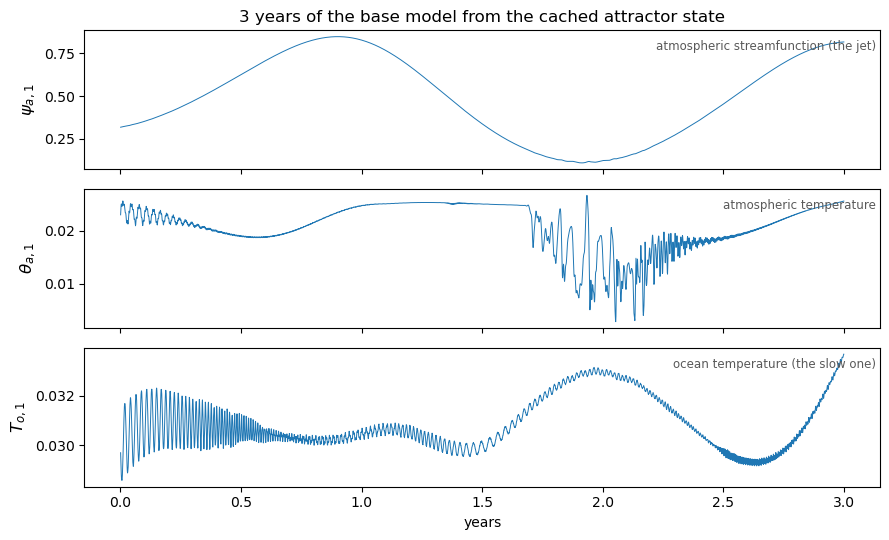

In [5]:
x_attr = get_attractor_ic(tw, cfg)

WRITE_EVERY = 30                                   # 0.34 d per sample: resolves weather
n_steps = config.days_to_steps(365 * 3)
traj = np.asarray(jm.integrate(tw.T_base, x_attr, config.DT, n_steps, write_every=WRITE_EVERY))
years = config.steps_to_days(np.arange(1, len(traj) + 1) * WRITE_EVERY) / 365.0

MODES = [(tw.idx_psia1,   r"$\psi_{a,1}$", "atmospheric streamfunction (the jet)"),
         (tw.idx_thetaa1, r"$\theta_{a,1}$", "atmospheric temperature"),
         (tw.idx_To1,     r"$T_{o,1}$", "ocean temperature (the slow one)")]

plt = inline()
fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True)
for ax, (k, sym, desc) in zip(axes, MODES):
    ax.plot(years, traj[:, k], lw=0.7)
    ax.set_ylabel(sym, fontsize=12)
    ax.text(0.995, 0.93, desc, transform=ax.transAxes, ha="right", va="top",
            fontsize=8.5, color="0.35")
axes[-1].set_xlabel("years")
axes[0].set_title("3 years of the base model from the cached attractor state")
fig.tight_layout(); plt.show()

## 2. The injected error

The "truth" model is the base model plus a known, state-dependent error in the
atmosphere–ocean thermal exchange:

$$f_\text{true}(x) \;=\; f_\text{base}(x) \;+\; \varepsilon\, g(x)\,(E x),$$

with $E$ the constant exchange operator and
$g(x) = a_0 + a_1\theta_{a,1} + a_2 T_{o,1} + a_3\psi_{a,1}$. The discovery model has the
same shape with a *learnable* coefficient vector $c$, so the truth sits inside the model
class exactly, at `c_true = eps * g_coeffs`. The project default is $\varepsilon = 0.1$ and
$g(x) = T_{o,1}$ — one nonzero entry.

Note how small the error is relative to the base tendency. That is not incidental: the
`--climatology` study exists to show this error is climatologically *silent*, which is what
makes being able to discover it worth anything.

c_true      = [0.  0.  0.1 0. ]    (= eps * g_coeffs)
features(x) =  (1, theta_a1, T_o1, psi_a1)  -> [1.      0.023   0.02969 0.31767]

||m|| / ||f_base||  =  3.577e-05
E acts on rows 10..35 (the theta_a and T_o blocks) — 18 of 36


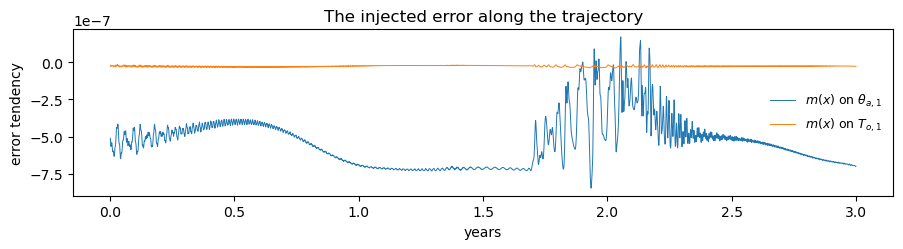

In [6]:
print("c_true      =", np.asarray(tw.c_true), "   (= eps * g_coeffs)")
print("features(x) =  (1, theta_a1, T_o1, psi_a1)  ->",
      np.round(np.asarray(tw.features(jnp.asarray(traj[0]))), 5))

m_err = formfit.err_tendency(tw, traj)                      # m(x) = f_true(x) - f_base(x)
f_base = np.asarray(jax.vmap(lambda x: tw.f_base(x))(jnp.asarray(traj)))
print(f"\n||m|| / ||f_base||  =  {np.linalg.norm(m_err)/np.linalg.norm(f_base):.3e}")

rows = np.where(np.abs(np.asarray(tw.E_full)).sum(1) > 0)[0]
print(f"E acts on rows {rows.min()}..{rows.max()} "
      f"(the theta_a and T_o blocks) — {len(rows)} of {tw.ndim}")

plt = inline()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(years, m_err[:, tw.idx_thetaa1], lw=0.7, label=r"$m(x)$ on $\theta_{a,1}$")
ax.plot(years, m_err[:, tw.idx_To1], lw=0.7, label=r"$m(x)$ on $T_{o,1}$")
ax.set_xlabel("years"); ax.set_ylabel("error tendency")
ax.set_title("The injected error along the trajectory")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

## 3. Known form, unknown magnitude

The easier of the two problems: assume the *form* of the error is known and recover only its
four coefficients. Because the model class contains the truth, this is a nonlinear least
squares problem with a known global minimum and zero residual in the noiseless limit.
`discovery.recover` rolls the discovery model through RK4, scores it against the truth
trajectory, and fits $c$ by Levenberg–Marquardt on the autodiff residual Jacobian.

The diagnostic that matters is $\mathrm{cond}(J^\top J)$ — the conditioning of the
parameter → observation map. Watch it collapse as the window lengthens past the
under-determined regime.

In [7]:
mask = obs_mask(tw.ndim, vr, "full")           # observe all 36; try "atmos" / "ocean" / "temp"
Y_true = np.asarray(discovery.rollout(lambda y: tw.f_true(y), x_attr, config.DT, 5120))

print(f"{'window':>8} {'days':>7}  {'rel_err':>10}  {'cond(JtJ)':>11}  {'rank':>4}   c_hat")
for w in (40, 320, 1280, 5120):
    r = discovery.recover(tw, x_attr, Y_true[:w], config.DT, mask, eta=0.0, n_iters=cfg.lm_iters)
    print(f"{w:8d} {config.steps_to_days(w):7.2f}  {r['rel_err']:10.2e}  "
          f"{r['cond']:11.2e}  {r['rank']:4d}   {np.round(r['c_hat'], 6)}")

  window    days     rel_err    cond(JtJ)  rank   c_hat


      40    0.45    1.87e-03     5.99e+14     4   [ 5.4000e-05  1.8000e-05  9.9931e-02 -1.6400e-04]


     320    3.59    2.81e-10     2.88e+08     4   [ 0.   0.   0.1 -0. ]


    1280   14.36    6.32e-11     1.76e+07     4   [-0.   0.   0.1  0. ]


    5120   57.42    8.43e-11     4.34e+08     4   [-0.  -0.   0.1 -0. ]


At half a day the four coefficients are barely separable — `cond(JtJ)` is ~$10^{15}$ and the
recovery is only good to $10^{-3}$. By a few days it is at machine precision. Sweeping that
window properly, and adding observation noise, is what the default study does.

## 4. The `run()` / `figure()` contract — one real study

Every study module answers to the same pair, both callable with no arguments:

```python
run(...)      # computes, writes .npz to RESULTS_DIR, returns its results
figure(...)   # reloads that .npz, draws, returns the list of paths written
```

`run` never draws and `figure` never computes, so a figure can be re-rendered from cached
results without repeating the expensive part. That is what makes §7's re-render loop cost
seconds.

**One trap worth knowing before you use it.** `--quick` swaps in `config.QUICK`, a smoke-test
preset — and `QUICK.spinup_steps` is 50,000, not the default 800,000. `get_attractor_ic`
checks the recipe, sees a mismatch, and **rebuilds and overwrites the shared IC cache**. The
next study you run rebuilds it again, at about two minutes a time. So this notebook builds
its own preset instead: `QUICK` with the default spin-up put back, and its own `tag`.

In [8]:
NB = dataclasses.replace(
    config.QUICK,
    spinup_steps=config.ExperimentConfig().spinup_steps,   # keep the shared cache valid
    tag="notebook",                                        # own filenames; won't touch "main"
)
print("notebook preset:", {f.name: getattr(NB, f.name) for f in dataclasses.fields(NB)
                           if getattr(NB, f.name) != getattr(config.ExperimentConfig(), f.name)})

from error_discovery.experiments import leadtime

t0 = time.time()
leadtime.run(NB)
print(f"\n[run took {time.time()-t0:.1f}s]")

notebook preset: {'n_ic': 2, 'window_steps': (160, 1280, 5120), 'noise_levels': (0.001,), 'noise_windows': (1280,), 'n_noise_seeds': 1, 'lm_iters': 8, 'lyap_blocks': 20, 'tag': 'notebook'}


[setup] ndim=36 eps=0.1 g_coeffs=(0.0, 0.0, 1.0, 0.0) obs=full c_true=[0.  0.  0.1 0. ]
[ic]    loaded cached attractor IC (/Users/aipa1027/Library/CloudStorage/OneDrive-UCB-O365/Documents/research/da_climate_model_improvements/dqgs_project/dqgs/error_discovery/results/attractor_ic.npz)


[lyap]  lambda_max=0.007515/nondim  tau_lyap=14.9 days (weakly chaotic; context only)


[clean] w=  160 (  1.79 d)  rel_err med=4.968e-01  cond(J) med=1.00e+05  smin med=3.50e-07  rank med=4


[clean] w= 1280 ( 14.36 d)  rel_err med=3.284e-01  cond(J) med=6.25e+03  smin med=8.47e-05  rank med=4


[clean] w= 5120 ( 57.42 d)  rel_err med=7.100e-01  cond(J) med=2.66e+04  smin med=3.66e-04  rank med=4


[noise] eta=1e-03  rel_err med over windows=[1.13607939]
[done]  wrote /Users/aipa1027/Library/CloudStorage/OneDrive-UCB-O365/Documents/research/da_climate_model_improvements/dqgs_project/dqgs/error_discovery/results/leadtime_notebook.npz  (16.7s total)

[run took 16.7s]


== error-discovery summary [notebook] ==
eps=0.1  g_coeffs=[0. 0. 1. 0.]  obs=full
tau_lyap ~ 15 days (weakly chaotic; context)
optimal window: 14.4 d  (rel_err=3.28e-01, cond=4.3e+07)
shortest window 1.79 d: rel_err=4.97e-01, cond=1.3e+10
longest window  57.4 d: rel_err=7.10e-01, cond=7.4e+08
noiseless rel_err>0.1 first at: 14.4 d
  eta=1e-03: median rel_err over windows=[1.14]  (<0.1 at [] d)
fig_recovery_conditioning_notebook.png
fig_coeff_recovery_notebook.png
fig_noise_notebook.png


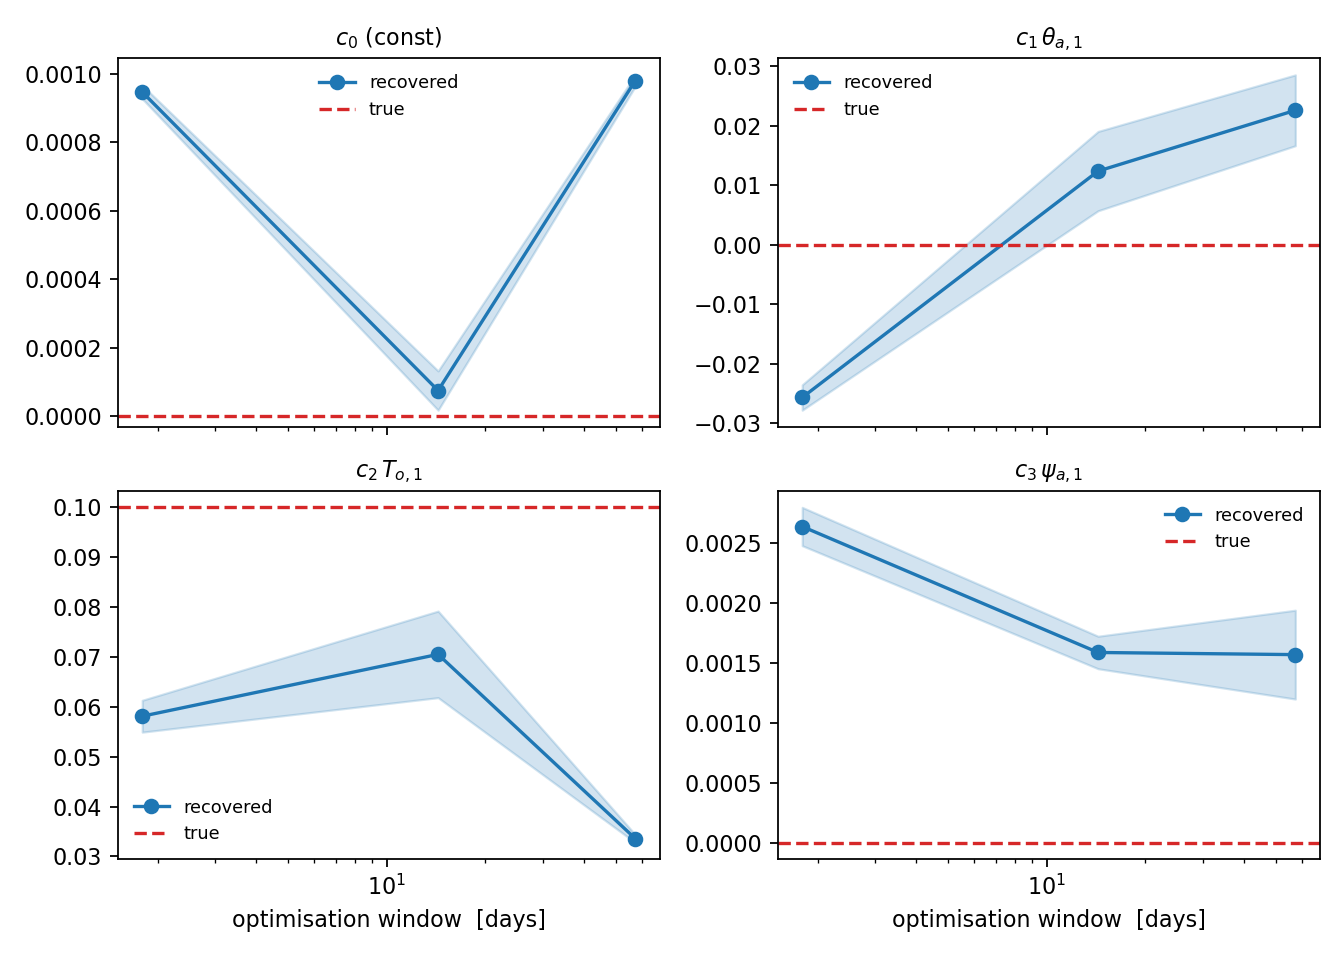

In [9]:
figs = leadtime.figure("notebook")     # reloads leadtime_notebook.npz, draws, returns paths
for f in figs:
    print(os.path.basename(f))
display(Image(figs[1]))                # coefficient recovery vs window

## 5. Unknown form — the harder problem, and the project's headline

Now drop the assumption that the form is known. The injected error enters *linearly* in a
candidate library ($E$ is constant), so each candidate $g_j$ has a closed-form best
coefficient and no optimizer is involved at all. The verdict is the **margin**: the best
*wrong* form's relative residual minus the true form's. Positive means the truth wins;
`config.THRESH` is where it counts as identifiable.

The central asymmetry of the whole project is what the same fit does on two different
distributions — the model's own attractor, versus an off-attractor transient.

In [10]:
N = 3000
X_att = formfit.attractor_traj(tw, N)              # the base model's own climatology
X_off = formfit.transient_traj(tw, N, seed=0)      # released from a random state
true_name = formfit.true_term(tw)                  # "x28" -> the T_o1 driver

print(f"true form: {true_name}   THRESH = {config.THRESH}\n")
print(f"{'distribution':>16}  {'margin':>9}  {'truth best?':>11}  {'max|mean|/std':>13}  verdict")
for label, X in (("on-attractor", X_att), ("off-attractor", X_off)):
    m = formfit.err_tendency(tw, X)
    c, names = formfit.fit(tw, X, m)
    R = formfit.resid(tw, c, X, m)
    margin, is_best = formfit.margin_named(R, names, true_name)
    verdict = "identifiable" if margin > config.THRESH else "NOT identifiable"
    print(f"{label:>16}  {margin:+9.4f}  {str(bool(is_best)):>11}  "
          f"{screening.max_mean_over_std(X):13.1f}  {verdict}")

true form: x28   THRESH = 0.1

    distribution     margin  truth best?  max|mean|/std  verdict
    on-attractor    +0.0331         True          710.6  NOT identifiable
   off-attractor    +0.9668         True          308.1  identifiable


Same error, same library, same fit — identifiable off the attractor, not on it. The truth is
still the single best fit on the attractor, but it beats the best wrong form by too little to
call.

`max|mean|/std` is the diagnostic behind that. A mode that never crosses zero over the
sample is near-constant; multiply any candidate driver by such a mode and you get back a
rescaled copy of the driver, which the fit cannot distinguish from the truth. `--obstruction`
and `--why` develop this into the governing law, and `--robustness` tests how far it holds.

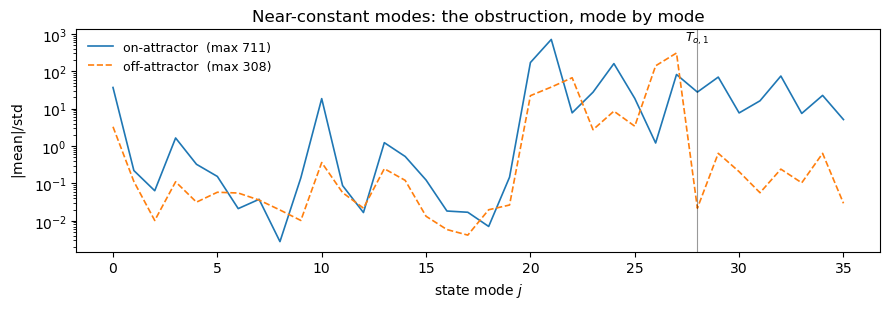

In [11]:
plt = inline()          # section 4's figure() switched the process to Agg; switch back
fig, ax = plt.subplots(figsize=(9, 3.2))
for label, X, style in (("on-attractor", X_att, "-"), ("off-attractor", X_off, "--")):
    ms = [screening.mean_over_std(X, j) for j in range(tw.ndim)]
    ax.semilogy(ms, style, lw=1.2, label=f"{label}  (max {max(ms):.0f})")
ax.axvline(tw.idx_To1, color="k", lw=0.8, alpha=0.4)
ax.annotate("$T_{o,1}$", (tw.idx_To1, ax.get_ylim()[1]), fontsize=9,
            ha="center", va="top")
ax.set_xlabel("state mode $j$"); ax.set_ylabel(r"$|\mathrm{mean}|/\mathrm{std}$")
ax.set_title("Near-constant modes: the obstruction, mode by mode")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

## 6. The alias mechanism — the second real run

`--alias` is the picture of *why*, in three panels: the near-constant mode times a candidate
driver, on the attractor and under broad excitation.

⚠️ Unlike §4 this study has no `tag`, so it rewrites the tracked `results/fig_alias.png`.
§9 shows how to put it back.

att    corr(d, m*d) = +1.000   |mean|/std of m on the attractor = 171.4
broad  corr(d, m*d) = -0.004   |mean|/std of m on the attractor = 171.4
[3.9s] fig_alias.png


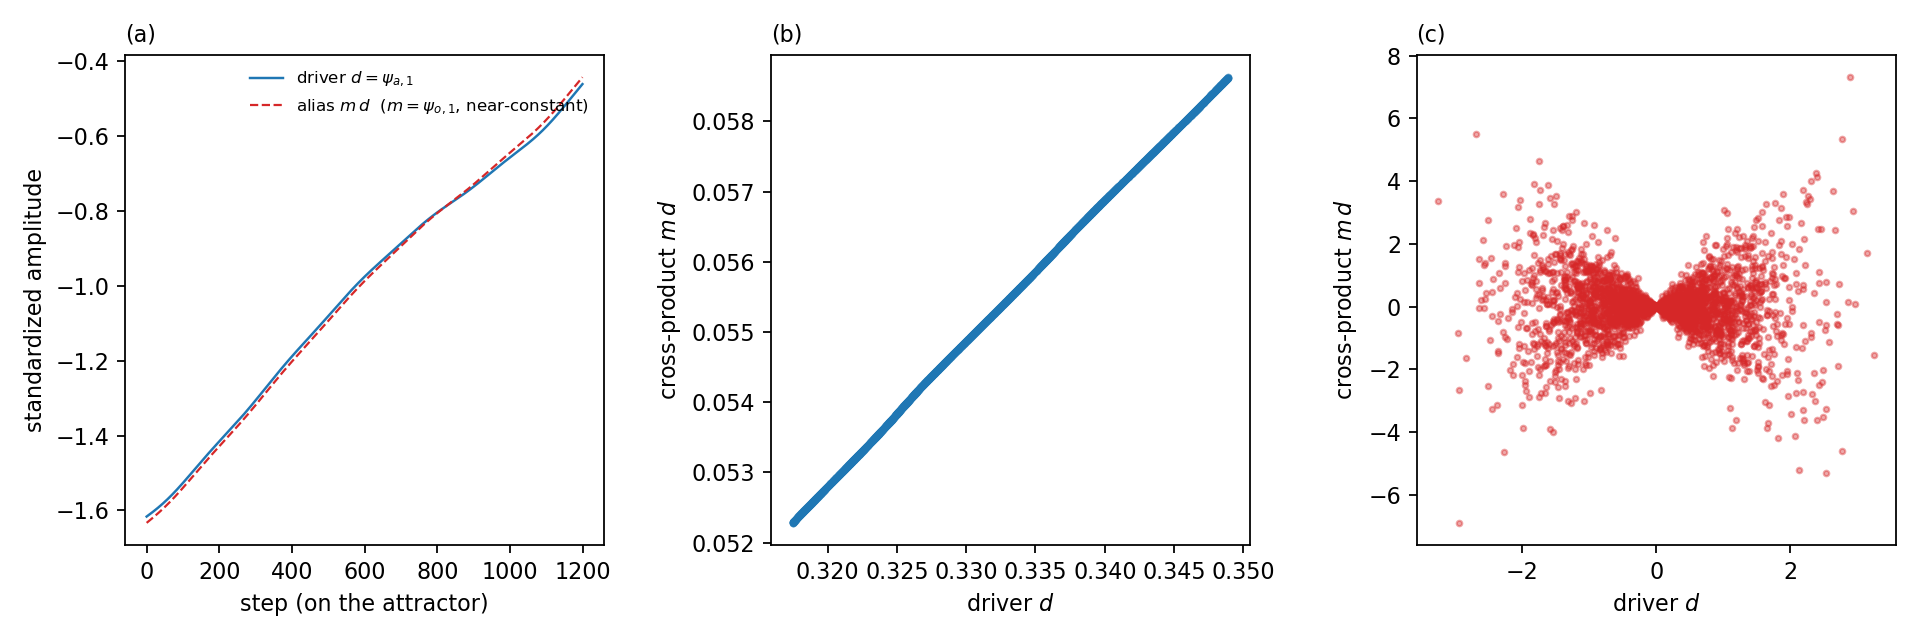

In [12]:
from error_discovery.experiments import alias

t0 = time.time()
alias.run()                              # -> results/alias.npz
figs = alias.figure()                    # -> results/fig_alias.png
print(f"[{time.time()-t0:.1f}s]", *[os.path.basename(f) for f in figs])
display(Image(figs[0]))

## 7. Driving it from the command line

A study's knobs are its own keyword arguments. `--set key=value` reaches them and
`--list-params` lists them, both read off `inspect.signature` over the functions the study
actually calls — so there is no second list to keep in sync, and exposing a knob means
giving it a keyword argument, nothing more.

Values are parsed against the *type* of the default, which is why `--set whiten=false` means
false rather than the truthy string `"false"`.

In [13]:
def cli(*args):
    r = subprocess.run([sys.executable, "-m", "error_discovery.run_all", *args],
                       capture_output=True, text=True)
    print(r.stdout or r.stderr)

cli("--param-tuning", "--list-params")

--param-tuning: parameters, set with --set key=value

  window    = 40                             [run]
  n_windows = 6                              [run]
  spinup    = 40000                          [run]
  gap       = 2000                           [run]
  n_iters   = 300                            [run]
  lr        = 0.05                           [run]
  beta1     = 0.9                            [run]
  beta2     = 0.999                          [run]
  seed      = 2024                           [run]
  verbose   = True                           [run]



```bash
python -m error_discovery.run_all --driver-scan --set n=8000 --set reps=40
python -m error_discovery.run_all --set whiten=true --set tag=main_whiten   # manuscript Fig. 2
python -m error_discovery.run_all --param-tuning --set lr=0.01 --set n_iters=800
```

And because `figure()` never computes, every study redraws from its cached `.npz` in a few
seconds. This loop is the only check that covers the drawing code and the `STUDIES` table —
no test calls any `run()` or `figure()`.

In [14]:
import contextlib, io as _io
from error_discovery import run_all

t0 = time.time(); rendered, failed = [], []
for name, s in run_all.STUDIES.items():
    if s.figure is None:                      # --oracle prints a table, writes nothing
        continue
    try:
        with contextlib.redirect_stdout(_io.StringIO()):   # studies narrate; we want the tally
            rendered += [(name, len(getattr(run_all._load(name), s.figure)()))]
    except Exception as e:
        failed += [(name, f"{type(e).__name__}: {e}")]

print(f"\nre-rendered {len(rendered)} studies in {time.time()-t0:.1f}s, {len(failed)} failed")
for n, e in failed:
    print("  FAIL", n, e)


re-rendered 18 studies in 2.8s, 0 failed


## 8. The warm-up: tuning physical parameters

`--param-tuning` is the easy version of the problem, and the contrast that makes the rest of
the package worth doing. The model has the *right structure* but wrong constants: two
friction coefficients and a radiative coupling scale are corrupted by 25–30%, and Adam walks
them back through the RK4 integrator to ~$10^{-8}$.

Nothing about a real missing term is that obliging. Tuning `kd` cannot fix a missing
convection scheme, which is why every other study here is about an error whose *form* is
unknown.

Redrawn from cache below. `run()` also stores the full optimiser history — the loss, the
gradient, and the effective Adam step at every iteration — so how it converged can be asked
of the `.npz` without paying for the run again.

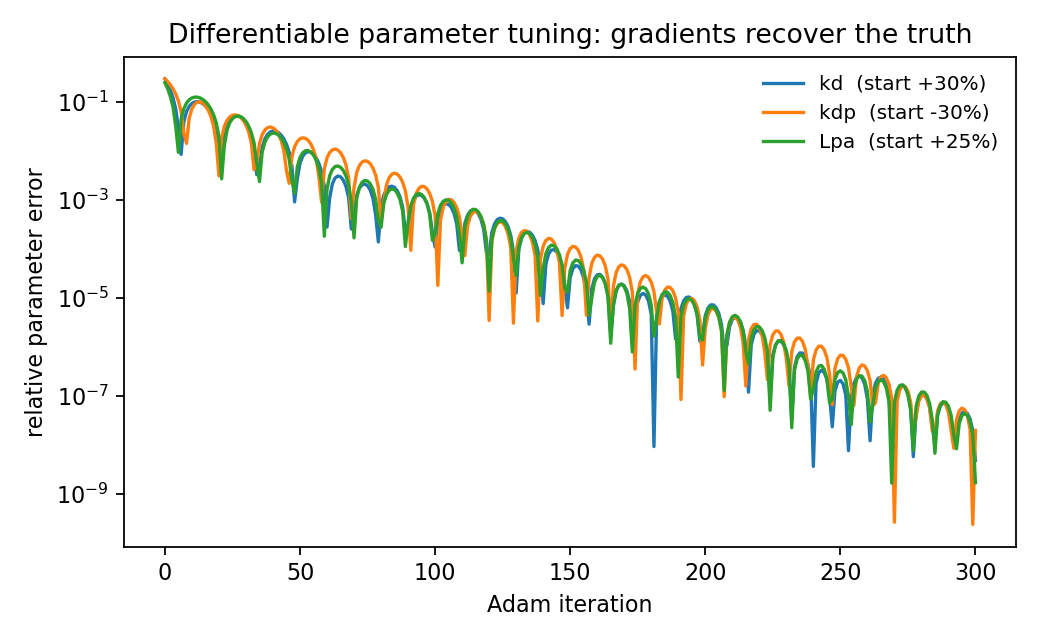

stored per-iteration history: {'z': (301, 3), 'loss': (300,), 'grad': (300, 3), 'step': (300, 3)}
optimiser settings: {'lr': 0.05, 'beta1': 0.9, 'beta2': 0.999, 'n_iters': 300}
final relative error: [4.82827400e-09 1.96957162e-08 1.69840675e-09]


In [15]:
from error_discovery.experiments import param_tuning

display(Image(param_tuning.figure()[0]))

d = np.load(os.path.join(config.RESULTS_DIR, "param_tuning.npz"))
print("stored per-iteration history:",
      {k: d[k].shape for k in ("z", "loss", "grad", "step")})
print("optimiser settings:",
      {k: d[k].item() for k in ("lr", "beta1", "beta2", "n_iters")})
print("final relative error:", np.abs(np.exp(d["z"][-1]) - 1.0))

## 9. What this notebook changed

§4 wrote `leadtime_notebook.npz` and three `fig_*_notebook.png`, which nothing else reads.
§6 and §7 rewrote tracked PNGs under `results/`. Figures do not need to be bit-reproducible
here — only the numbers do — so the usual move is simply to drop the pixel churn.

In [16]:
repo = os.path.dirname(os.path.dirname(config.RESULTS_DIR))
print(subprocess.run(["git", "status", "--short", "error_discovery/results"],
                     cwd=repo, capture_output=True, text=True).stdout or "(nothing changed)")
print("to discard the redrawn figures:\n"
      "    git checkout -- error_discovery/results")
print("to remove this notebook's own outputs:\n"
      "    rm error_discovery/results/*_notebook.*")

 M error_discovery/results/fig_alias.png
 M error_discovery/results/fig_climatology.png
 M error_discovery/results/fig_coeff_recovery_main.png
 M error_discovery/results/fig_decomposition.png
 M error_discovery/results/fig_donoharm.png
 M error_discovery/results/fig_driver.png
 M error_discovery/results/fig_driver_collapse.png
 M error_discovery/results/fig_form_discovery.png
 M error_discovery/results/fig_form_identifiability.png
 M error_discovery/results/fig_increment.png
 M error_discovery/results/fig_jax_validation.png
 M error_discovery/results/fig_meanstd.png
 M error_discovery/results/fig_noise_main.png
 M error_discovery/results/fig_overcomplete.png
 M error_discovery/results/fig_param_tuning.png
 M error_discovery/results/fig_reanalysis.png
 M error_discovery/results/fig_recovery_conditioning_main.png
 M error_discovery/results/fig_roadmap.png
 M error_discovery/results/fig_robustness.png
 M error_discovery/results/fig_sparsity_noise_sparsity.png
 M error_discovery/results/fi